# Entendimiento de los datos: Novedades

Este notebook trabaja **solo** con el conjunto de datos de *Novedades* (`Novedad20260603.zip`). No se usan los datos de Preconteo ni de Escrutinio.

In [1]:
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path('../../data/raw/elecciones_2026/extracted/MMV_Presidente1V_2026/MMV_Presidente1V_2026')
NOVEDADES_ZIP = DATA_DIR / 'Novedad20260603.zip'

# Estilo de las gráficas: azul como color principal, naranja para lo que requiere atención, gris para el contexto
AZUL, AZUL_CLARO, NARANJA, GRIS = '#2a78d6', '#86b6ef', '#eb6834', '#c3c2b7'
TINTA, TINTA_SUAVE, FONDO = '#0b0b0b', '#52514e', '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'savefig.facecolor': FONDO,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': GRIS,
    'axes.labelcolor': TINTA_SUAVE, 'xtick.color': TINTA_SUAVE, 'ytick.color': TINTA_SUAVE,
    'text.color': TINTA, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'axes.grid.axis': 'x', 'grid.color': '#e1e0d9', 'grid.linewidth': 0.8,
    'axes.axisbelow': True,
})


def miles(n):
    return f'{n:,.0f}'.replace(',', '.')


def porcentaje(x, decimales=1):
    return f'{x:.{decimales}f} %'.replace('.', ',')


## Carga de datos

In [2]:
def fix_bad_line(fields):
    # 45 filas traen comas sin comillas en puestoNombre (columna 7): se vuelven a unir
    extra = len(fields) - 24
    if extra < 1:
        return None
    return fields[:7] + [','.join(fields[7:8 + extra])] + fields[8 + extra:]


with zipfile.ZipFile(NOVEDADES_ZIP) as z:
    with z.open('Novedad20260603.csv') as f:
        df = pd.read_csv(f, dtype=str, engine='python', on_bad_lines=fix_bad_line)

print(df.shape)
df.head()


(118350, 24)


,id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,...,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos
0,010100101011,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,1,001,...,BUENO,NO,NO,NO,NO,6,128,0,128,127
1,010100101012,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,2,001,...,BUENO,NO,NO,NO,NO,6,65,0,65,65
2,010100101013,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,3,001,...,BUENO,NO,NO,NO,NO,6,107,0,107,107
3,010100101014,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,4,001,...,BUENO,NO,NO,NO,NO,6,143,0,143,143
4,010100101015,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA No 2,5,001,...,BUENO,NO,NO,NO,NO,6,177,0,177,177


## Estructura general

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 118350 entries, 0 to 118349
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   id                      118350 non-null  str  
 1   departamentoCodigo      118350 non-null  str  
 2   departamentoNombre      118350 non-null  str  
 3   municipioCodigo         118350 non-null  str  
 4   municipioNombre         118350 non-null  str  
 5   zonaNombre              118350 non-null  str  
 6   puestoCodigo            118350 non-null  str  
 7   puestoNombre            118350 non-null  str  
 8   mesaNumero              118350 non-null  str  
 9   corporacionCodigo       118350 non-null  str  
 10  corporacionNombre       118350 non-null  str  
 11  potencial               118350 non-null  str  
 12  sufragantesSegunE11     118350 non-null  str  
 13  enTerminos              118350 non-null  str  
 14  estadoSobre             118350 non-null  str  
 15  tachadurasE

In [4]:
df.isna().sum()

id                        0
departamentoCodigo        0
departamentoNombre        0
municipioCodigo           0
municipioNombre           0
zonaNombre                0
puestoCodigo              0
puestoNombre              0
mesaNumero                0
corporacionCodigo         0
corporacionNombre         0
potencial                 0
sufragantesSegunE11       0
enTerminos                0
estadoSobre               0
tachadurasEnmendaduras    0
recontadaJurados          0
recontadaComision         0
excluida                  0
firmasJurados             0
votosUrna                 0
votosIncinerados          0
sufragantesE11SegunE14    0
totalVotos                0
dtype: int64

In [5]:
df.describe(include='all').T

,count,unique,top,freq
id,118350,118350,010100101011,1
departamentoCodigo,118350,33,16,17164
departamentoNombre,118350,33,BOGOTA D.C.,17164
municipioCodigo,118350,263,001,52074
municipioNombre,118350,1036,BOGOTA. D.C.,17164
zonaNombre,118350,42,99,19365
puestoCodigo,118350,208,01,23961
puestoNombre,118350,10485,PUESTO CABECERA MUNICIPAL,11780
mesaNumero,118350,228,1,13489
corporacionCodigo,118350,1,001,118350


### Novedades registradas

Cuántas mesas presentan cada tipo de novedad.

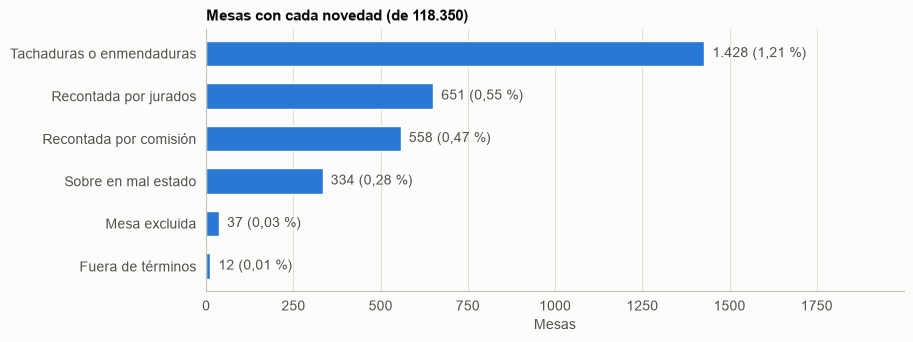

In [6]:
novedades = {
    'Tachaduras o enmendaduras': df['tachadurasEnmendaduras'].eq('SI'),
    'Recontada por jurados': df['recontadaJurados'].eq('SI'),
    'Recontada por comisión': df['recontadaComision'].eq('SI'),
    'Sobre en mal estado': df['estadoSobre'].eq('MAL'),
    'Mesa excluida': df['excluida'].eq('SI'),
    'Fuera de términos': df['enTerminos'].eq('NO'),
}
conteo_novedades = pd.Series({k: int(v.sum()) for k, v in novedades.items()}).sort_values()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(conteo_novedades.index, conteo_novedades.values, color=AZUL, height=0.6)
for y, n in enumerate(conteo_novedades.values):
    ax.text(n, y, f'  {miles(n)} ({porcentaje(n / len(df) * 100, 2)})', va='center', color=TINTA_SUAVE)
ax.set_xlim(0, conteo_novedades.max() * 1.4)
ax.set_xlabel('Mesas')
ax.set_title(f'Mesas con cada novedad (de {miles(len(df))})')
plt.show()

# Preprocesamiento

Secciones:
1. Valores faltantes, duplicados y atípicos
2. Inconsistencias
3. Limpieza de los datos
4. Documentación de las decisiones tomadas

En las secciones 1 y 2 solo se **diagnostica**; las transformaciones se aplican en la sección 3 sobre una copia (`df_clean`) y cada decisión se registra en la sección 4.

## 1. Valores faltantes, duplicados y atípicos

### 1.1 Valores faltantes

In [7]:
COLS_NUM = ['mesaNumero', 'potencial', 'sufragantesSegunE11', 'firmasJurados', 'votosUrna',
            'votosIncinerados', 'sufragantesE11SegunE14', 'totalVotos']

nulos = df.isna().sum().sum()
vacios = df.apply(lambda s: s.str.strip().eq('')).sum().sum()
print(f'Nulos: {nulos} | Cadenas vacías: {vacios}')

# Las columnas numéricas llegan como texto (dtype=str): se verifica que todas se puedan convertir
df_num = df[COLS_NUM].apply(pd.to_numeric, errors='coerce')
print('Valores no numéricos por columna:')
print(df_num.isna().sum().to_string())

Nulos: 0 | Cadenas vacías: 0
Valores no numéricos por columna:
mesaNumero                0
potencial                 0
sufragantesSegunE11       0
firmasJurados             0
votosUrna                 0
votosIncinerados          0
sufragantesE11SegunE14    0
totalVotos                0


**Hallazgo:** no hay nulos, cadenas vacías ni valores no numéricos en las columnas de conteo.

### 1.2 Duplicados

In [8]:
CLAVE_MESA = ['departamentoCodigo', 'municipioCodigo', 'zonaNombre', 'puestoCodigo', 'mesaNumero']

print('Filas completamente duplicadas:', df.duplicated().sum())
print('Valores de id repetidos:', df['id'].duplicated().sum())
print('Mesas repetidas (departamento, municipio, zona, puesto, mesa):', df.duplicated(subset=CLAVE_MESA).sum())
print('Filas iguales ignorando id:', df.drop(columns='id').duplicated().sum())

Filas completamente duplicadas: 0
Valores de id repetidos: 0
Mesas repetidas (departamento, municipio, zona, puesto, mesa): 0
Filas iguales ignorando id: 0


**Hallazgo:** no hay duplicados exactos, de `id` ni de mesa. Cada fila es una mesa única.

### 1.3 Valores atípicos

Se usa el rango intercuartílico (IQR): son atípicos los valores fuera de `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]`, donde Q1 y Q3 son los cuartiles 25 y 75 e IQR = Q3 − Q1. Se aplica a las cuatro columnas de votantes.

In [9]:
print('Valores de potencial:', df_num['potencial'].value_counts().to_dict())

COLS_VOTOS = ['sufragantesSegunE11', 'votosUrna', 'votosIncinerados', 'sufragantesE11SegunE14', 'totalVotos']


def limites_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


resumen = []
for col in COLS_VOTOS:
    lo, hi = limites_iqr(df_num[col])
    resumen.append({
        'columna': col,
        'limite_inf': lo,
        'limite_sup': hi,
        'atipicos_iqr': ((df_num[col] < lo) | (df_num[col] > hi)).sum(),
        'p99': df_num[col].quantile(0.99),
        'maximo': df_num[col].max(),
    })
pd.DataFrame(resumen).set_index('columna')

Valores de potencial: {360: 117022, 800: 572, 500: 467, 1200: 289}


,limite_inf,limite_sup,atipicos_iqr,p99,maximo
columna,,,,,
sufragantesSegunE11,22.0,382.0,1504,325.0,800
votosUrna,22.0,382.0,1702,324.0,8195
votosIncinerados,0.0,0.0,2112,1.0,360
sufragantesE11SegunE14,22.0,382.0,1562,327.0,3025
totalVotos,22.0,382.0,1538,323.0,546


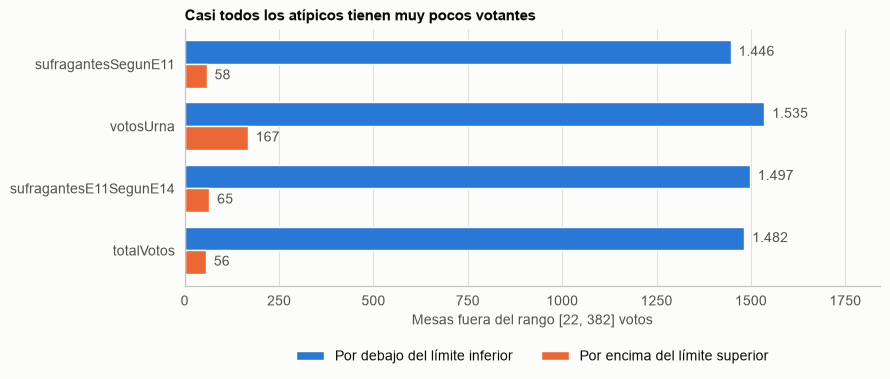

In [10]:
COLS_IQR = ['sufragantesSegunE11', 'votosUrna', 'sufragantesE11SegunE14', 'totalVotos']

limites = {col: limites_iqr(df_num[col]) for col in COLS_IQR}
por_debajo = {col: int((df_num[col] < limites[col][0]).sum()) for col in COLS_IQR}
por_encima = {col: int((df_num[col] > limites[col][1]).sum()) for col in COLS_IQR}

fig, ax = plt.subplots(figsize=(9, 4))

# Atípicos por IQR, según el lado del límite
posiciones = range(len(COLS_IQR))
alto = 0.38
ax.barh([p - alto / 2 for p in posiciones], list(por_debajo.values()), height=alto, color=AZUL,
        label='Por debajo del límite inferior')
ax.barh([p + alto / 2 for p in posiciones], list(por_encima.values()), height=alto, color=NARANJA,
        label='Por encima del límite superior')
for p, (a, b) in enumerate(zip(por_debajo.values(), por_encima.values())):
    ax.text(a, p - alto / 2, f'  {miles(a)}', va='center', color=TINTA_SUAVE)
    ax.text(b, p + alto / 2, f'  {miles(b)}', va='center', color=TINTA_SUAVE)
ax.set_yticks(list(posiciones), COLS_IQR)
ax.set_xlim(0, max(por_debajo.values()) * 1.2)
ax.invert_yaxis()
lo, hi = limites['sufragantesSegunE11']
ax.set_xlabel(f'Mesas fuera del rango [{lo:.0f}, {hi:.0f}] votos')
ax.set_title('Casi todos los atípicos tienen muy pocos votantes')
ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.2))

fig.tight_layout()
plt.show()

**Lectura:**
- El IQR marca entre 1.504 y 1.702 mesas por columna de votantes, con los mismos límites en las cuatro: de 22 a 382 votos.
- Casi todas están por debajo del límite inferior, es decir, mesas con menos de 22 votantes (incluidas las excluidas). Por encima del límite hay pocas (56 a 167 por columna), pero incluyen los extremos 8.195 y 3.025.

La decisión sobre estas mesas se toma en la sección 3.

### 1.4 Efecto de leer todas las columnas como texto (`dtype=str`)

El archivo se carga con `dtype=str` para conservar los ceros a la izquierda de los códigos. Riesgos: `isna()` solo detecta lo que pandas convierte a `NaN`, `describe()` e `info()` no resumen conteos y ordenar compara carácter a carácter. Se verifica cada punto.

In [11]:
# 1) Lectura sin ninguna conversión automática a NaN, para comparar con la lectura normal
with zipfile.ZipFile(NOVEDADES_ZIP) as z:
    with z.open('Novedad20260603.csv') as f:
        df_raw = pd.read_csv(f, dtype=str, engine='python', on_bad_lines=fix_bad_line,
                             keep_default_na=False, na_filter=False)

print('Celdas distintas entre ambas lecturas:', int((df.fillna('<NA>') != df_raw).sum().sum()))

MARCADORES = {'', '-', '--', '?', 'NA', 'N/A', 'NULL', 'NAN', 'NONE', 'S/D', 'SD', 'SIN DATO', 'NO APLICA'}
marcadores = df_raw.apply(lambda s: s.str.strip().str.upper().isin(MARCADORES)).sum()
print('Celdas con marcadores de dato ausente:', int(marcadores.sum()))

# 2) Las columnas de conteo deben ser solo dígitos (to_numeric también aceptaría '5.0', '+5', ' 5' o '1e3')
no_digitos = {c: int((~df[c].str.fullmatch(r'\d+')).sum()) for c in COLS_NUM}
print('Conteos que no son solo dígitos:', no_digitos)

# 3) Códigos: ¿alguno no es numérico? (si lo fuera, convertirlo a entero habría fallado o perdido información)
CODIGOS = ['departamentoCodigo', 'municipioCodigo', 'zonaNombre', 'puestoCodigo', 'corporacionCodigo']
print('Códigos no numéricos:', {c: int((~df[c].str.fullmatch(r'\d+')).sum()) for c in CODIGOS})
print('Ejemplos de puestoCodigo no numérico:', df.loc[~df['puestoCodigo'].str.fullmatch(r'\d+'), 'puestoCodigo'].unique()[:8].tolist())

# 4) Máximo como texto frente al máximo numérico
print('Máximo de votosUrna como texto:', df['votosUrna'].max(), '| como número:', df_num['votosUrna'].max())

Celdas distintas entre ambas lecturas: 0
Celdas con marcadores de dato ausente: 0
Conteos que no son solo dígitos: {'mesaNumero': 0, 'potencial': 0, 'sufragantesSegunE11': 0, 'firmasJurados': 0, 'votosUrna': 0, 'votosIncinerados': 0, 'sufragantesE11SegunE14': 0, 'totalVotos': 0}
Códigos no numéricos: {'departamentoCodigo': 0, 'municipioCodigo': 0, 'zonaNombre': 0, 'puestoCodigo': 931, 'corporacionCodigo': 0}
Ejemplos de puestoCodigo no numérico: ['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'B1', 'B2']
Máximo de votosUrna como texto: 990 | como número: 8195


**Lectura:**
- Los 0 nulos son reales: la lectura sin conversión automática da las mismas celdas y no hay marcadores como `-` o `S/D`.
- Los conteos son solo dígitos, así que `to_numeric` no acepta formatos raros.
- Los códigos deben quedarse como texto: `puestoCodigo` tiene 931 filas alfanuméricas (`A1`, `B2`, ...) y los demás tienen ceros a la izquierda.
- El texto engaña al ordenar (el máximo de `votosUrna` es `990` como texto y `8195` como número); los análisis numéricos deben usar `df_num` o `df_clean`.
- Por la misma razón, `df.info()` y `df.describe()` del inicio no resumen los conteos.

## 2. Inconsistencias

### 2.1 Coherencia del identificador y de los códigos

El `id` se compone de un prefijo `01` más los códigos de departamento, municipio, zona, puesto y mesa. Se verifica que coincida con las columnas y que cada código tenga un único nombre dentro de su nivel jerárquico (el código de municipio se repite entre departamentos, por lo que se evalúa junto con el del departamento).

In [12]:
id_esperado = '01' + df['departamentoCodigo'] + df['municipioCodigo'] + df['zonaNombre'] + df['puestoCodigo'] + df['mesaNumero']
print('Filas donde el id no coincide con sus códigos:', (id_esperado != df['id']).sum())
print('Códigos de corporación distintos:', df['corporacionCodigo'].unique().tolist(), df['corporacionNombre'].unique().tolist())

JERARQUIA = {
    'departamento': (['departamentoCodigo'], 'departamentoNombre'),
    'municipio': (['departamentoCodigo', 'municipioCodigo'], 'municipioNombre'),
    'puesto': (['departamentoCodigo', 'municipioCodigo', 'zonaNombre', 'puestoCodigo'], 'puestoNombre'),
}
pd.Series({
    nivel: int(df.groupby(claves)[nombre].nunique().gt(1).sum())
    for nivel, (claves, nombre) in JERARQUIA.items()
}, name='códigos con más de un nombre')

Filas donde el id no coincide con sus códigos: 0
Códigos de corporación distintos: ['001'] ['PRESIDENTE']


departamento    0
municipio       0
puesto          0
Name: códigos con más de un nombre, dtype: int64

**Hallazgo:** el `id` coincide con sus códigos en todas las filas, `corporacionCodigo` es constante (`001`, PRESIDENTE) y ningún código tiene más de un nombre. No hay inconsistencias en la jerarquía territorial.

### 2.2 Formato del texto

Se buscan espacios al inicio o al final, espacios dobles y minúsculas en las columnas de texto.

In [13]:
COLS_TEXTO = [c for c in df.columns if c not in COLS_NUM]

formato = pd.DataFrame({
    'espacios_borde': {c: (df[c] != df[c].str.strip()).sum() for c in COLS_TEXTO},
    'espacios_dobles': {c: df[c].str.contains('  ', regex=False).sum() for c in COLS_TEXTO},
    'con_minusculas': {c: (df[c] != df[c].str.upper()).sum() for c in COLS_TEXTO},
})
formato[formato.sum(axis=1) > 0]

,espacios_borde,espacios_dobles,con_minusculas
puestoNombre,21,1251,535


**Hallazgo:** solo `puestoNombre` tiene problemas de formato: 21 filas con espacios en los extremos, 1251 con espacios dobles y 535 con minúsculas. Las demás columnas de texto están normalizadas.

### 2.3 Consistencia entre los conteos de votos

Se asume que `sufragantesSegunE11`, `votosUrna` y `sufragantesE11SegunE14` describen la participación de la misma mesa y, por tanto, deberían ser iguales o muy cercanas, y que `totalVotos` no debería superarlas. Esta suposición conviene contrastarla con la documentación de los formularios E-11 y E-14. Se mide cuántas mesas no coinciden y por cuánto.

In [14]:
PARES = [
    ('votosUrna', 'sufragantesSegunE11'),
    ('votosUrna', 'sufragantesE11SegunE14'),
    ('sufragantesSegunE11', 'sufragantesE11SegunE14'),
]
BINS = [-1, 0, 5, 50, float('inf')]
ETIQUETAS = ['0 (coinciden)', '1 a 5', '6 a 50', 'más de 50']

diferencias = pd.DataFrame({
    f'{a} vs {b}': pd.cut((df_num[a] - df_num[b]).abs(), bins=BINS, labels=ETIQUETAS).value_counts()
    for a, b in PARES
}).loc[ETIQUETAS]
display(diferencias)

excesos = {
    'totalVotos > votosUrna': df_num['totalVotos'] > df_num['votosUrna'],
    'totalVotos > sufragantesSegunE11': df_num['totalVotos'] > df_num['sufragantesSegunE11'],
    'totalVotos > sufragantesE11SegunE14': df_num['totalVotos'] > df_num['sufragantesE11SegunE14'],
}
pd.Series({k: v.sum() for k, v in excesos.items()}, name='filas')

,votosUrna vs sufragantesSegunE11,votosUrna vs sufragantesE11SegunE14,sufragantesSegunE11 vs sufragantesE11SegunE14
0 (coinciden),112628,112742,117162
1 a 5,5101,4868,736
6 a 50,175,110,106
más de 50,446,630,346


totalVotos > votosUrna                 343
totalVotos > sufragantesSegunE11         2
totalVotos > sufragantesE11SegunE14    203
Name: filas, dtype: int64

**Hallazgo:** `votosUrna` es la que más se aleja de las otras (5.722 mesas distintas de `sufragantesSegunE11`, 446 con más de 50 votos de diferencia). `totalVotos` supera a `votosUrna` en 343 mesas y a `sufragantesE11SegunE14` en 203. La sección 2.5 lo muestra en gráficas.

### 2.4 Consistencia de las banderas de novedad

Se revisa si las banderas (`excluida`, `enTerminos`, recuentos, firmas) son coherentes con los conteos.

In [15]:
print('excluida vs totalVotos == 0')
display(pd.crosstab(df['excluida'], df_num['totalVotos'].eq(0), rownames=['excluida'], colnames=['totalVotos == 0']))

print('enTerminos vs excluida')
display(pd.crosstab(df['enTerminos'], df['excluida']))

print('Recontadas por jurados y por comisión a la vez:',
      ((df['recontadaJurados'] == 'SI') & (df['recontadaComision'] == 'SI')).sum())
print('Mesas con 0 firmas de jurados:', (df_num['firmasJurados'] == 0).sum())
print('Mesas no excluidas con 0 sufragantes:',
      ((df_num['sufragantesSegunE11'] == 0) & (df['excluida'] == 'NO')).sum())

excluida vs totalVotos == 0


totalVotos == 0,False,True
excluida,,
NO,118313,0
SI,0,37


enTerminos vs excluida


excluida,NO,SI
enTerminos,,
NO,7,5
SI,118306,32


Recontadas por jurados y por comisión a la vez: 20
Mesas con 0 firmas de jurados: 104
Mesas no excluidas con 0 sufragantes: 1


**Hallazgos:**
- `excluida` es coherente con `totalVotos`: las 37 mesas excluidas tienen 0 votos y ninguna otra mesa tiene 0.
- 12 mesas están fuera de términos (`enTerminos = NO`); 5 de ellas están excluidas y 7 no.
- 20 mesas figuran recontadas tanto por jurados como por comisión. Es posible, pero se deja marcado para revisión.
- 104 mesas tienen 0 firmas de jurados. No se corrige: es información sobre la mesa, no un error de captura.

### Resumen de la sección 2

| Inconsistencia | Filas afectadas | Tratamiento propuesto (sección 3) |
|---|---|---|
| `puestoNombre` con espacios en los extremos o dobles | 21 y 1251 | Normalizar espacios |
| `puestoNombre` con minúsculas | 535 | Pasar a mayúsculas |
| `votosUrna` difiere de `sufragantesSegunE11` por más de 50 | 446 | Marcar con una bandera |
| `totalVotos` > `votosUrna` | 343 | Marcar con una bandera |
| `totalVotos` > `sufragantesE11SegunE14` | 203 | Marcar con una bandera |

Los identificadores, la jerarquía territorial y la relación entre `excluida` y `totalVotos` no presentan inconsistencias.

### 2.5 Comparación de las cuatro variables de votantes

Para ver de forma sencilla si hay consistencia, se comparan `sufragantesSegunE11`, `sufragantesE11SegunE14`, `votosUrna` y `totalVotos` mesa por mesa. Se usan solo las mesas no excluidas, porque las excluidas tienen `totalVotos` en 0 y distorsionarían la comparación.

**Resumen general:** totales y valores típicos de cada variable.

In [16]:
VARS = ['sufragantesSegunE11', 'sufragantesE11SegunE14', 'votosUrna', 'totalVotos']
mesas = df_num.loc[df['excluida'] == 'NO', VARS]

print(f'Mesas comparadas: {len(mesas):,}')
mesas.agg(['sum', 'mean', 'median', 'max']).T.round(1)

Mesas comparadas: 118,313


,sum,mean,median,max
sufragantesSegunE11,23435460.0,198.1,206.0,800.0
sufragantesE11SegunE14,23465025.0,198.3,206.0,3025.0
votosUrna,23586462.0,199.4,206.0,8195.0
totalVotos,23399401.0,197.8,206.0,546.0


**Coincidencia entre pares de variables:** porcentaje de mesas donde dos variables son iguales.

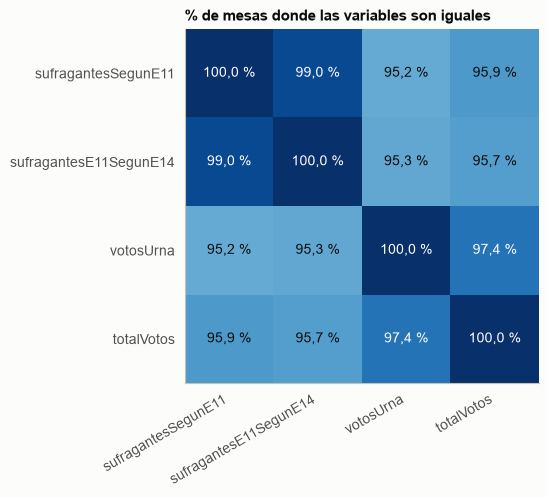

In [17]:
def porcentaje_coincidencia(tolerancia):
    return pd.DataFrame({
        a: {b: ((mesas[a] - mesas[b]).abs() <= tolerancia).mean() * 100 for b in VARS}
        for a in VARS
    })


coincidencia = porcentaje_coincidencia(0)

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.imshow(coincidencia.values, cmap='Blues', vmin=90, vmax=100)
ax.set_xticks(range(len(VARS)), VARS, rotation=30, ha='right')
ax.set_yticks(range(len(VARS)), VARS)
ax.grid(False)
for i in range(len(VARS)):
    for j in range(len(VARS)):
        valor = coincidencia.iloc[i, j]
        ax.text(j, i, porcentaje(valor), ha='center', va='center',
                color='white' if valor >= 96 else TINTA)
ax.set_title('% de mesas donde las variables son iguales')
plt.show()

**Tamaño de la diferencia:** se toma `sufragantesSegunE11` como referencia y se mide cuánto se desvía cada una de las otras tres variables.

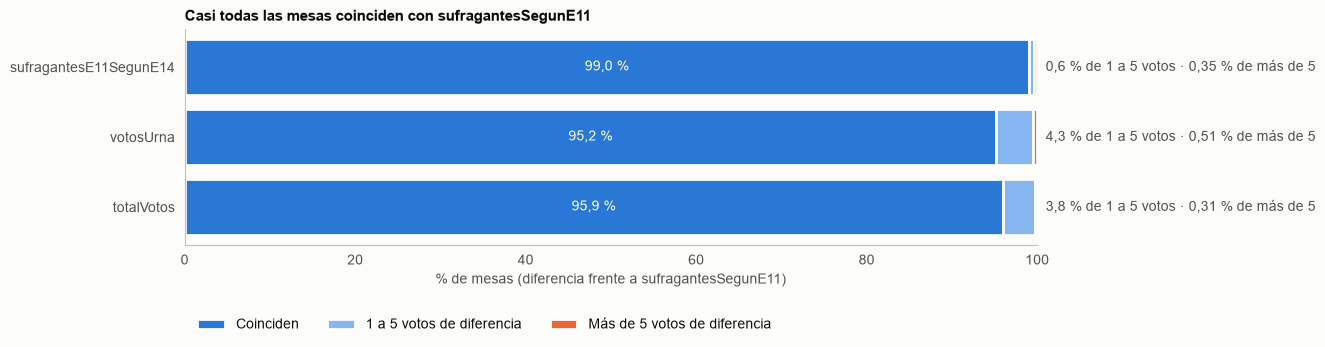

,sufragantesE11SegunE14,votosUrna,totalVotos
mayor que la referencia,0.45,1.39,0.00
igual,99.02,95.18,95.93
menor que la referencia,0.52,3.44,4.07


In [18]:
referencia = mesas['sufragantesSegunE11']
otras = VARS[1:]
dif = pd.DataFrame({v: (mesas[v] - referencia).abs() for v in otras})

grupos = pd.DataFrame({
    'Coinciden': dif.eq(0).mean(),
    '1 a 5 votos de diferencia': (dif.gt(0) & dif.le(5)).mean(),
    'Más de 5 votos de diferencia': dif.gt(5).mean(),
}) * 100

fig, ax = plt.subplots(figsize=(11, 2.8))
acumulado = pd.Series(0.0, index=grupos.index)
for columna, color in zip(grupos.columns, [AZUL, AZUL_CLARO, NARANJA]):
    ax.barh(grupos.index, grupos[columna], left=acumulado, color=color,
            edgecolor=FONDO, linewidth=2, label=columna)
    if columna == 'Coinciden':
        for y, valor in enumerate(grupos[columna]):
            ax.text(valor / 2, y, porcentaje(valor), ha='center', va='center', color='white')
    acumulado += grupos[columna]
for y, (leve, grave) in enumerate(zip(grupos.iloc[:, 1], grupos.iloc[:, 2])):
    ax.text(101, y, f'{porcentaje(leve)} de 1 a 5 votos · {porcentaje(grave, 2)} de más de 5',
            va='center', color=TINTA_SUAVE)

ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.grid(False)
ax.set_xlabel('% de mesas (diferencia frente a sufragantesSegunE11)')
ax.set_title('Casi todas las mesas coinciden con sufragantesSegunE11')
ax.legend(ncol=3, frameon=False, loc='upper left', bbox_to_anchor=(0, -0.28))
plt.show()

# Sentido de la diferencia (% de mesas)
pd.DataFrame({
    v: {
        'mayor que la referencia': (mesas[v] > referencia).mean() * 100,
        'igual': (mesas[v] == referencia).mean() * 100,
        'menor que la referencia': (mesas[v] < referencia).mean() * 100,
    }
    for v in otras
}).round(2)

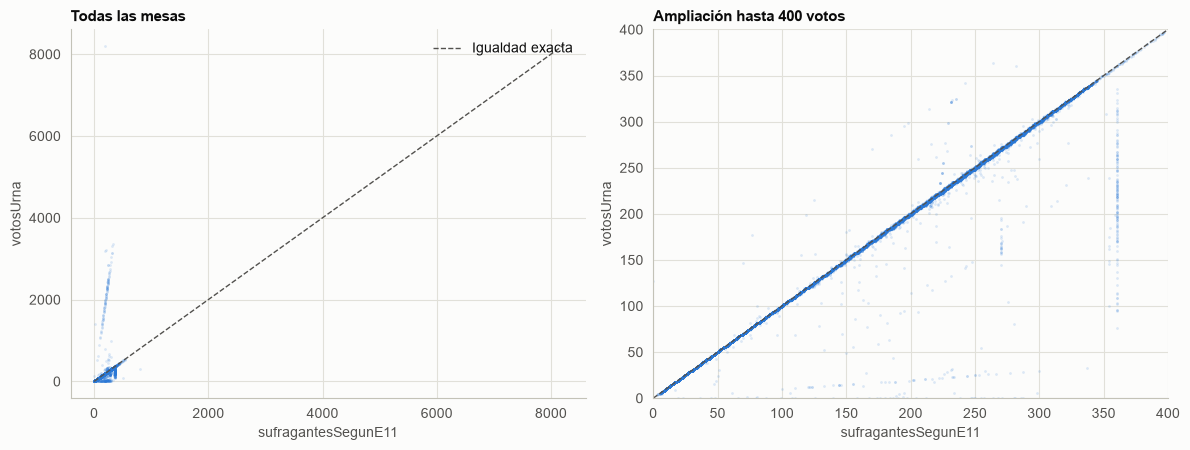

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, limite, titulo in [(ax1, None, 'Todas las mesas'), (ax2, 400, 'Ampliación hasta 400 votos')]:
    ax.scatter(mesas['sufragantesSegunE11'], mesas['votosUrna'],
               s=4, color=AZUL, alpha=0.15, linewidths=0, rasterized=True)
    tope = limite or mesas['votosUrna'].max()
    ax.plot([0, tope], [0, tope], color=TINTA_SUAVE, linestyle='--', linewidth=1)
    if limite:
        ax.set_xlim(0, limite)
        ax.set_ylim(0, limite)
    ax.grid(True, axis='both')
    ax.set_xlabel('sufragantesSegunE11')
    ax.set_ylabel('votosUrna')
    ax.set_title(titulo)

ax1.plot([], [], color=TINTA_SUAVE, linestyle='--', linewidth=1, label='Igualdad exacta')
ax1.legend(frameon=False, loc='upper right')
fig.tight_layout()
plt.show()

**Lectura:**
- Las cuatro variables son consistentes: frente a `sufragantesSegunE11`, coinciden exactamente en más del 95 % de las mesas y difieren en 5 votos o menos en más del 99 %. La mediana es 206 en todas.
- `sufragantesE11SegunE14` replica a `sufragantesSegunE11` (99 % iguales).
- `votosUrna` es la que más se desvía y tiene el máximo más alto de las cuatro (8.195); su suma total sube por esos valores extremos.
- `totalVotos` nunca supera a `sufragantesSegunE11` (salvo 2 mesas). Es compatible con que cuente solo una parte de los votantes, pero no está confirmado con la documentación.

## 3. Limpieza de los datos

Criterios:
- Se trabaja sobre una copia (`df_clean`); `df` queda intacto para poder comparar.
- Los atípicos se excluyen con un único criterio: el IQR sobre las cuatro columnas de votantes. Las mesas excluidas se guardan aparte en `df_atipicos`.
- Las inconsistencias entre conteos no modifican valores: solo se marcan con banderas.

### 3.1 Normalización de texto

In [20]:
df_clean = df.copy()

# Espacios en los extremos y dobles, y minúsculas (solo puestoNombre presenta estos problemas)
df_clean['puestoNombre'] = (
    df_clean['puestoNombre']
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
    .str.upper()
)

formato_clean = pd.DataFrame({
    'espacios_borde': {c: (df_clean[c] != df_clean[c].str.strip()).sum() for c in COLS_TEXTO},
    'espacios_dobles': {c: df_clean[c].str.contains('  ', regex=False).sum() for c in COLS_TEXTO},
    'con_minusculas': {c: (df_clean[c] != df_clean[c].str.upper()).sum() for c in COLS_TEXTO},
})
print('Problemas de formato restantes:', int(formato_clean.sum().sum()))

# Cada puesto debe seguir teniendo un único nombre
claves, nombre = JERARQUIA['puesto']
print('Puestos con más de un nombre:', int(df_clean.groupby(claves)[nombre].nunique().gt(1).sum()))

Problemas de formato restantes: 0
Puestos con más de un nombre: 0


### 3.2 Tipos de datos

Las columnas de conteo pasan a enteros con soporte de nulos (`Int64`) y las columnas SI/NO a booleanas. Los códigos (departamento, municipio, zona, puesto, corporación) se mantienen como texto: tienen ceros a la izquierda y `puestoCodigo` incluye valores alfanuméricos (`A1`, `B2`, ...), como se verificó en la sección 1.4.

In [21]:
COLS_SI_NO = ['enTerminos', 'tachadurasEnmendaduras', 'recontadaJurados', 'recontadaComision', 'excluida']

df_clean[COLS_NUM] = df_clean[COLS_NUM].apply(pd.to_numeric).astype('Int64')

for col in COLS_SI_NO:
    assert df_clean[col].isin(['SI', 'NO']).all(), col
    df_clean[col] = df_clean[col].eq('SI')

df_clean['estadoSobre'] = df_clean['estadoSobre'].astype('category')
df_clean.dtypes.to_frame('tipo').T

,id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,...,estadoSobre,tachadurasEnmendaduras,recontadaJurados,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos
tipo,str,str,str,str,str,str,str,str,Int64,str,...,category,bool,bool,bool,bool,Int64,Int64,Int64,Int64,Int64


### 3.3 Banderas de inconsistencia

Una diferencia entre conteos puede deberse a un error en cualquiera de las columnas, así que no se corrige ningún valor: solo se marcan.
- `urna_difiere_e11`: `votosUrna` y `sufragantesSegunE11` difieren en más de 50 votos.
- `total_mayor_urna` y `total_mayor_e14`: `totalVotos` supera a `votosUrna` o a `sufragantesE11SegunE14`.

In [22]:
df_clean['urna_difiere_e11'] = (df_clean['votosUrna'] - df_clean['sufragantesSegunE11']).abs() > 50
df_clean['total_mayor_urna'] = df_clean['totalVotos'] > df_clean['votosUrna']
df_clean['total_mayor_e14'] = df_clean['totalVotos'] > df_clean['sufragantesE11SegunE14']

COLS_BANDERAS = ['urna_difiere_e11', 'total_mayor_urna', 'total_mayor_e14']
print('Filas marcadas por bandera (antes de excluir atípicos):')
print(df_clean[COLS_BANDERAS].sum().to_string())

Filas marcadas por bandera (antes de excluir atípicos):
urna_difiere_e11    446
total_mayor_urna    343
total_mayor_e14     203


### 3.4 Exclusión de atípicos con IQR

Se excluye toda mesa que quede fuera de los límites del IQR en al menos una de las cuatro columnas de votantes (`COLS_IQR`). Las mesas excluidas se guardan en `df_atipicos` para poder revisarlas, y se muestra cuántas novedades contienen.

In [23]:
es_atipica = pd.concat(
    [(df_num[col] < lo) | (df_num[col] > hi) for col, (lo, hi) in limites.items()],
    axis=1,
).any(axis=1)

df_atipicos = df_clean[es_atipica]
df_clean = df_clean[~es_atipica]

print(f'Mesas excluidas por IQR: {miles(len(df_atipicos))} ({porcentaje(len(df_atipicos) / len(df) * 100, 2)})')

# Novedades que se pierden con la exclusión (reutiliza el diccionario `novedades` del inicio)
perdidas = pd.DataFrame({
    'total': {k: int(v.sum()) for k, v in novedades.items()},
    'excluidas_por_iqr': {k: int((v & es_atipica).sum()) for k, v in novedades.items()},
})
perdidas['% perdido'] = (perdidas['excluidas_por_iqr'] / perdidas['total'] * 100).round(1)
perdidas

Mesas excluidas por IQR: 1.746 (1,48 %)


,total,excluidas_por_iqr,% perdido
Tachaduras o enmendaduras,1428,24,1.7
Recontada por jurados,651,2,0.3
Recontada por comisión,558,5,0.9
Sobre en mal estado,334,7,2.1
Mesa excluida,37,37,100.0
Fuera de términos,12,6,50.0


**Lectura:** se excluyen 1.746 mesas (1,48 %), casi todas por tener menos de 22 votantes. La exclusión por IQR también elimina novedades: las 37 mesas con `excluida = SI` (100 %) y 6 de las 12 fuera de términos. Si el análisis posterior se centra en esas novedades, conviene revisar `df_atipicos` antes de descartarlas.

### 3.5 Validación de la limpieza

In [24]:
print('Filas originales / limpias / excluidas por IQR:',
      miles(len(df)), '/', miles(len(df_clean)), '/', miles(len(df_atipicos)))
print('id únicos:', df_clean['id'].is_unique)
print('Nulos en df_clean:', int(df_clean.isna().sum().sum()))
print('Rango de los conteos tras la exclusión:')
display(df_clean[COLS_IQR].agg(['min', 'max']))
df_clean.head()

Filas originales / limpias / excluidas por IQR: 118.350 / 116.604 / 1.746
id únicos: True
Nulos en df_clean: 0
Rango de los conteos tras la exclusión:


,sufragantesSegunE11,votosUrna,sufragantesE11SegunE14,totalVotos
min,22,22,22,22
max,381,381,381,381


,id,departamentoCodigo,departamentoNombre,municipioCodigo,municipioNombre,zonaNombre,puestoCodigo,puestoNombre,mesaNumero,corporacionCodigo,...,recontadaComision,excluida,firmasJurados,votosUrna,votosIncinerados,sufragantesE11SegunE14,totalVotos,urna_difiere_e11,total_mayor_urna,total_mayor_e14
0,010100101011,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA NO 2,1,001,...,False,False,6,128,0,128,127,False,False,False
1,010100101012,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA NO 2,2,001,...,False,False,6,65,0,65,65,False,False,False
2,010100101013,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA NO 2,3,001,...,False,False,6,107,0,107,107,False,False,False
3,010100101014,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA NO 2,4,001,...,False,False,6,143,0,143,143,False,False,False
4,010100101015,01,ANTIOQUIA,001,MEDELLIN,01,01,SEC. ESC. LA ESPERANZA NO 2,5,001,...,False,False,6,177,0,177,177,False,False,False


## 4. Documentación de las decisiones tomadas

### 4.1 Registro de decisiones

| # | Hallazgo | Filas | Decisión | Justificación | Alternativa descartada |
|---|---|---|---|---|---|
| 1 | Coma sin comillas en `puestoNombre` del CSV (error de carga) | 45 | Reunir los campos sobrantes con `on_bad_lines` | Las filas son válidas; solo les falta el entrecomillado del campo | Descartar las filas con `on_bad_lines='skip'` (se perderían mesas) |
| 2 | Valores faltantes | 0 | Ninguna | No hay nulos ni cadenas vacías | — |
| 3 | Duplicados (fila, `id` o mesa) | 0 | Ninguna | Cada fila es una mesa única | — |
| 4 | `puestoNombre` con espacios en los extremos, espacios dobles y minúsculas | 21 / 1251 / 535 | Quitar espacios y pasar a mayúsculas | Unifica el formato sin cambiar el significado | Dejarlo igual (dificultaría agrupar por puesto) |
| 5 | Conteos y SI/NO como texto; `puestoCodigo` con valores alfanuméricos | todas | Conteos a `Int64`, SI/NO a booleano, códigos como texto | Permite operar sin perder ceros a la izquierda ni códigos como `A1` | Convertir los códigos a entero |
| 6 | Atípicos por IQR en las 4 columnas de votantes (límites 22 a 382) | 1.746 (1,48 %) | Excluir de `df_clean` y guardar en `df_atipicos` | Criterio único, objetivo y reproducible | Marcar sin excluir; excluir solo la cola superior |
| 7 | `potencial` y `votosIncinerados` | — | No se les aplica IQR | Su IQR es 0 (casi un solo valor) y marcaría 1.328 y 2.112 mesas legítimas | Aplicar el IQR a todas las columnas numéricas |
| 8 | `votosUrna` difiere de `sufragantesSegunE11` en más de 50 votos | 446 (247 tras excluir atípicos) | Solo bandera `urna_difiere_e11` | No se puede saber cuál de los dos conteos es el correcto | Imputar o anular uno de los dos |
| 9 | `totalVotos` > `votosUrna` o > `sufragantesE11SegunE14` | 343 / 203 (263 / 177 tras excluir) | Solo banderas `total_mayor_urna` y `total_mayor_e14` | Puede deberse a un error en cualquiera de las columnas | Corregir `totalVotos` |
| 10 | Mesas con alguna novedad (tachaduras, recuentos, sobre en mal estado, excluida, fuera de términos) | 2.898 | Se conservan, salvo las 67 que caen en el IQR (incluye las 37 con `excluida = SI`) | Son las novedades que estudia este conjunto | Proteger esas mesas de la exclusión |
| 11 | Id, jerarquía territorial y relación `excluida` / `totalVotos` | 0 | Ninguna | Son coherentes | — |

### 4.2 Supuestos y limitaciones

- Se asume que `sufragantesSegunE11`, `votosUrna` y `sufragantesE11SegunE14` deberían coincidir o ser muy cercanas. No está contrastado con la documentación de los formularios E-11 y E-14; si miden cosas distintas, las banderas 8 y 9 deben revisarse.
- El IQR se calcula sobre todo el conjunto, sin distinguir por `potencial`. Una mesa con muy poca asistencia, o una mesa grande (`potencial` 500, 800 o 1.200) con más de 382 votos, puede quedar excluida sin ser un error.
- La mayoría de los atípicos (cola inferior) son mesas con menos de 22 votantes. No se verificó si son errores o participación real muy baja.
- El umbral de 50 votos de `urna_difiere_e11` es arbitrario.
- Las mesas excluidas se conservan en `df_atipicos` y en `df`.

### 4.3 Comparación antes y después

In [25]:
def resumen_estado(datos):
    return {
        'filas': len(datos),
        'columnas': datos.shape[1],
        'nulos': int(datos.isna().sum().sum()),
        'máx. votosUrna': int(datos['votosUrna'].max()),
    }


pd.DataFrame({
    'df (original)': resumen_estado(df_num.join(df.drop(columns=COLS_NUM))),
    'df_clean': resumen_estado(df_clean),
}).T

,filas,columnas,nulos,máx. votosUrna
df (original),118350,24,0,8195
df_clean,116604,27,0,381


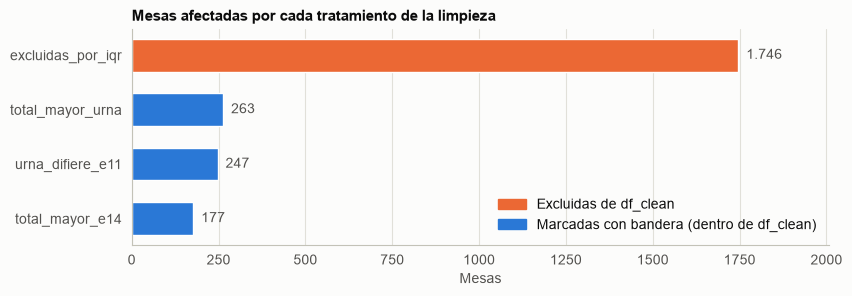

In [26]:
from matplotlib.patches import Patch

tratamientos = pd.concat([
    df_clean[COLS_BANDERAS].sum(),
    pd.Series({'excluidas_por_iqr': len(df_atipicos)}),
]).sort_values()

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(tratamientos.index, tratamientos.values, height=0.6,
        color=[NARANJA if c == 'excluidas_por_iqr' else AZUL for c in tratamientos.index])
for y, n in enumerate(tratamientos.values):
    ax.text(n, y, f'  {miles(n)}', va='center', color=TINTA_SUAVE)
ax.set_xlim(0, tratamientos.max() * 1.15)
ax.set_xlabel('Mesas')
ax.set_title('Mesas afectadas por cada tratamiento de la limpieza')
ax.legend(handles=[Patch(color=NARANJA, label='Excluidas de df_clean'),
                   Patch(color=AZUL, label='Marcadas con bandera (dentro de df_clean)')],
          frameon=False, loc='lower right')
plt.show()